Loaded 3,927 nodes and 31,004 interactions.
Full-network hub threshold: 0.0118186449312
Hubs: 393/3,927 (10.01%; ties included)
Dropped for low/missing pLDDT: 963
Dropped for excluded class after pLDDT filtering: 436
Structure-eligible nodes: 2,528
Structure-eligible nodes with missing class annotation: 0

Interactions involving at least one hub: 18,033
Hub–hub interactions before filtering: 9,194
Oriented hub–partner comparisons: 27,227
Comparisons with both endpoints structure-eligible: 21,556

METRIC COVERAGE


,Metric,Eligible hubs with metric,Hubs with >=1 usable partner,Eligible measured hubs without a usable partner,Structure-eligible oriented comparisons,Dropped: missing metric at either endpoint,Usable oriented comparisons
0,Ghosh-Dill-dG,357,357,0,21556,0,21556
1,cagiada-dG,357,357,0,21556,0,21556
2,Rosetta_best_total_score,357,357,0,21556,0,21556



PER-EDGE DESCRIPTIVE RESULTS
Positive hub-minus-partner values indicate a less-stable focal hub.


,Metric,Partner subset,Oriented comparisons,Unique interactions,Unique focal hubs,Median hub-minus-partner,Hub less stable (%),Hub more stable (%),Exact ties (%),"Fraction less stable, ties half-weighted"
0,Ghosh-Dill-dG,All partners,21556,13620,357,0.104644,51.090184,48.524773,0.385044,0.512827
1,Ghosh-Dill-dG,Non-hub partners,5684,5684,354,0.610425,54.714989,44.985925,0.299085,0.548645
2,Ghosh-Dill-dG,Hub partners,15872,7936,355,0.000000,49.792087,49.792087,0.415827,0.500000
3,cagiada-dG,All partners,21556,13620,357,0.074912,50.301540,49.698460,0.000000,0.503015
4,cagiada-dG,Non-hub partners,5684,5684,354,0.343994,51.143561,48.856439,0.000000,0.511436
5,cagiada-dG,Hub partners,15872,7936,355,0.000000,50.000000,50.000000,0.000000,0.500000
6,Rosetta_best_total_score,All partners,21556,13620,357,11.519500,50.825756,49.174244,0.000000,0.508258
7,Rosetta_best_total_score,Non-hub partners,5684,5684,354,54.445000,53.131597,46.868403,0.000000,0.531316
8,Rosetta_best_total_score,Hub partners,15872,7936,355,0.000000,50.000000,50.000000,0.000000,0.500000


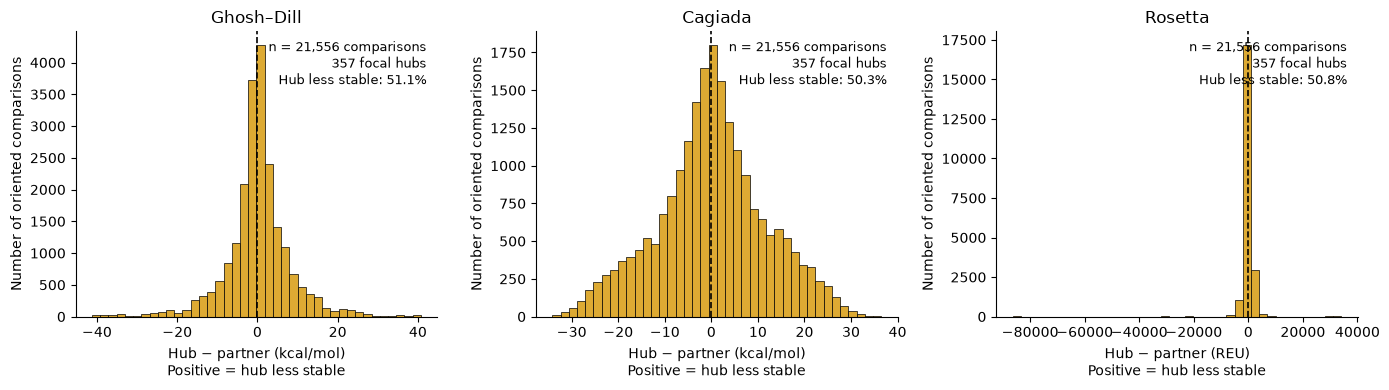

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display


# ============================================================
# Configuration
# ============================================================

NODES_FILE = Path(
    "../../18-finalize/processed-data/"
    "20260210-s288c-ANnnotated-Yeast-Interactome.pkl"
)
EDGES_FILE = Path(
    "../../0-download-inputs/data-files/The_Yeast_Interactome_edges.csv"
)

NODE_COLUMN = "node"
SOURCE_COLUMN = "source"
TARGET_COLUMN = "target"
CENTRALITY_COLUMN = "degree_centrality"
PLDDT_COLUMN = "mean_plddt"
CLASS_COLUMN = "DeepTMHMM_class"

HUB_FRACTION = 0.10
PLDDT_THRESHOLD = 70
EXCLUDED_CLASSES = ["TM", "SP+TM", "BETA"]

# Freshly loaded Cagiada values are assumed to require sign reversal,
# as in your Figure 3 notebook.
# Set to +1.0 if the FILE already stores folding-sign values.
CAGIADA_MULTIPLIER = -1.0

METRICS = {
    "Ghosh-Dill-dG": {
        "title": "Ghosh–Dill",
        "units": "kcal/mol",
        "multiplier": 1.0,
    },
    "cagiada-dG": {
        "title": "Cagiada",
        "units": "kcal/mol",
        "multiplier": CAGIADA_MULTIPLIER,
    },
    "Rosetta_best_total_score": {
        "title": "Rosetta",
        "units": "REU",
        "multiplier": 1.0,
    },
}

# Set True to write detailed comparison tables and summaries.
SAVE_OUTPUTS = False
OUTPUT_DIR = Path("processed-data/hub-partner-comparisons")


# ============================================================
# Load and validate inputs
# ============================================================

nodes = pd.read_pickle(NODES_FILE).copy()
edges = pd.read_csv(EDGES_FILE)

required_nodes = {
    NODE_COLUMN,
    CENTRALITY_COLUMN,
    PLDDT_COLUMN,
    CLASS_COLUMN,
    *METRICS,
}

for name, table, required in (
    ("Nodes", nodes, required_nodes),
    ("Edges", edges, {SOURCE_COLUMN, TARGET_COLUMN}),
):
    if not table.columns.is_unique:
        raise ValueError(f"{name}: duplicate column names.")

    missing = required - set(table.columns)
    if missing:
        raise ValueError(f"{name}: missing columns {sorted(missing)}")


def clean_identifiers(series, description):
    if series.isna().any():
        raise ValueError(f"{description}: missing identifiers.")

    if not series.map(lambda value: isinstance(value, str)).all():
        raise ValueError(f"{description}: non-string identifiers.")

    result = series.str.strip()

    if result.eq("").any():
        raise ValueError(f"{description}: blank identifiers.")

    return result


nodes[NODE_COLUMN] = clean_identifiers(
    nodes[NODE_COLUMN], "Node table"
)
edges[SOURCE_COLUMN] = clean_identifiers(
    edges[SOURCE_COLUMN], "Edge sources"
)
edges[TARGET_COLUMN] = clean_identifiers(
    edges[TARGET_COLUMN], "Edge targets"
)

if nodes[NODE_COLUMN].duplicated().any():
    duplicates = nodes.loc[
        nodes[NODE_COLUMN].duplicated(keep=False), NODE_COLUMN
    ].unique()
    raise ValueError(
        f"Duplicate node IDs: {duplicates[:10].tolist()}"
    )

# Match complete node labels exactly.
# Do not expand semicolon-delimited grouped nodes into invented edges.
endpoint_ids = set(edges[SOURCE_COLUMN]) | set(edges[TARGET_COLUMN])
unmatched_ids = endpoint_ids - set(nodes[NODE_COLUMN])

if unmatched_ids:
    raise ValueError(
        f"{len(unmatched_ids):,} edge endpoint IDs are absent from "
        f"the node table. Examples: {sorted(unmatched_ids)[:10]}"
    )

print(f"Loaded {len(nodes):,} nodes and {len(edges):,} interactions.")


# ============================================================
# Define hubs BEFORE filtering by structure or metric availability
# ============================================================

def numeric_finite(series):
    return pd.to_numeric(series, errors="coerce").replace(
        [np.inf, -np.inf], np.nan
    )


degree_centrality = numeric_finite(nodes[CENTRALITY_COLUMN])

# Require complete centrality information so the full-network cutoff
# and the hub/non-hub classification are unambiguous.
if degree_centrality.isna().any():
    raise ValueError(
        "Missing or invalid degree centrality in the node table."
    )

hub_threshold = degree_centrality.quantile(1 - HUB_FRACTION)
hub_mask = degree_centrality.ge(hub_threshold)
hub_ids = set(nodes.loc[hub_mask, NODE_COLUMN])

print(f"Full-network hub threshold: {hub_threshold:.12g}")
print(
    f"Hubs: {len(hub_ids):,}/{len(nodes):,} "
    f"({100 * len(hub_ids) / len(nodes):.2f}%; ties included)"
)


# ============================================================
# Structure eligibility: identical rules for hub and partner
# ============================================================

plddt = numeric_finite(nodes[PLDDT_COLUMN])
classes = nodes[CLASS_COLUMN].astype("string").str.strip()

passes_plddt = plddt.ge(PLDDT_THRESHOLD).fillna(False)
excluded_class = classes.isin(EXCLUDED_CLASSES)
structure_eligible = passes_plddt & ~excluded_class

# Preserve the existing exclusion-based class policy:
# missing classes are not automatically excluded.
missing_class = classes.isna() | classes.eq("").fillna(False)

print(f"Dropped for low/missing pLDDT: {(~passes_plddt).sum():,}")
print(
    "Dropped for excluded class after pLDDT filtering: "
    f"{(passes_plddt & excluded_class).sum():,}"
)
print(f"Structure-eligible nodes: {structure_eligible.sum():,}")
print(
    "Structure-eligible nodes with missing class annotation: "
    f"{(structure_eligible & missing_class).sum():,}"
)


# ============================================================
# Construct oriented hub–partner comparisons
# ============================================================

# An edge connecting a hub to a non-hub contributes one comparison.
# An edge connecting two hubs contributes two comparisons:
# A -> B and B -> A.
#
# This is deliberate: the unit is a focal hub–partner relationship.
# Consequently, higher-degree hubs contribute more observations.

edge_table = edges[[SOURCE_COLUMN, TARGET_COLUMN]].copy()
edge_table.insert(0, "edge_id", np.arange(len(edge_table)))

source_is_hub = edge_table[SOURCE_COLUMN].isin(hub_ids)
target_is_hub = edge_table[TARGET_COLUMN].isin(hub_ids)

forward = edge_table.loc[source_is_hub].rename(
    columns={
        SOURCE_COLUMN: "hub",
        TARGET_COLUMN: "partner",
    }
)

reverse = edge_table.loc[target_is_hub].rename(
    columns={
        TARGET_COLUMN: "hub",
        SOURCE_COLUMN: "partner",
    }
)

oriented_edges = pd.concat(
    [
        forward[["edge_id", "hub", "partner"]],
        reverse[["edge_id", "hub", "partner"]],
    ],
    ignore_index=True,
)

oriented_edges["partner_is_hub"] = oriented_edges["partner"].isin(hub_ids)

eligibility_lookup = pd.Series(
    structure_eligible.to_numpy(),
    index=nodes[NODE_COLUMN],
)

both_eligible = (
    oriented_edges["hub"].map(eligibility_lookup)
    & oriented_edges["partner"].map(eligibility_lookup)
)

eligible_edges = oriented_edges.loc[both_eligible].copy()

print(
    f"\nInteractions involving at least one hub: "
    f"{(source_is_hub | target_is_hub).sum():,}"
)
print(
    f"Hub–hub interactions before filtering: "
    f"{(source_is_hub & target_is_hub).sum():,}"
)
print(f"Oriented hub–partner comparisons: {len(oriented_edges):,}")
print(
    f"Comparisons with both endpoints structure-eligible: "
    f"{len(eligible_edges):,}"
)


# ============================================================
# Analyze each metric independently
# ============================================================

per_edge_results = {}
summary_rows = []
coverage_rows = []


def summarize_comparisons(table, metric, subset):
    difference = table["hub_minus_partner"].to_numpy()
    n = len(difference)

    less_stable = int((difference > 0).sum())
    more_stable = int((difference < 0).sum())
    tied = int((difference == 0).sum())

    return {
        "Metric": metric,
        "Partner subset": subset,
        "Oriented comparisons": n,
        "Unique interactions": table["edge_id"].nunique(),
        "Unique focal hubs": table["hub"].nunique(),
        "Median hub-minus-partner": (
            float(np.median(difference)) if n else np.nan
        ),
        "Hub less stable (%)": 100 * less_stable / n if n else np.nan,
        "Hub more stable (%)": 100 * more_stable / n if n else np.nan,
        "Exact ties (%)": 100 * tied / n if n else np.nan,
        "Fraction less stable, ties half-weighted": (
            (less_stable + 0.5 * tied) / n if n else np.nan
        ),
    }


for metric, settings in METRICS.items():
    # Transform a new Series; leave the loaded DataFrame unchanged.
    values = numeric_finite(nodes[metric]) * settings["multiplier"]
    lookup = pd.Series(values.to_numpy(), index=nodes[NODE_COLUMN])

    comparisons = eligible_edges.copy()
    comparisons["hub_value"] = comparisons["hub"].map(lookup)
    comparisons["partner_value"] = comparisons["partner"].map(lookup)

    valid = (
        np.isfinite(comparisons["hub_value"])
        & np.isfinite(comparisons["partner_value"])
    )

    comparisons = comparisons.loc[valid].copy()

    # For folding-sign ΔG and Rosetta, higher values indicate
    # less favorable folding energy / higher structural energy.
    comparisons["hub_minus_partner"] = (
        comparisons["hub_value"] - comparisons["partner_value"]
    )

    comparisons["hub_less_stable"] = comparisons["hub_minus_partner"] > 0
    comparisons["exact_tie"] = comparisons["hub_minus_partner"] == 0

    per_edge_results[metric] = comparisons

    measured_eligible_hubs = (
        hub_mask & structure_eligible & values.notna()
    ).sum()

    coverage_rows.append({
        "Metric": metric,
        "Eligible hubs with metric": int(measured_eligible_hubs),
        "Hubs with >=1 usable partner": comparisons["hub"].nunique(),
        "Eligible measured hubs without a usable partner": (
            int(measured_eligible_hubs) - comparisons["hub"].nunique()
        ),
        "Structure-eligible oriented comparisons": len(eligible_edges),
        "Dropped: missing metric at either endpoint": int((~valid).sum()),
        "Usable oriented comparisons": len(comparisons),
    })

    # Primary result includes every eligible partner.
    # The additional rows show the contribution of hub and non-hub partners.
    for subset, subset_table in (
        ("All partners", comparisons),
        (
            "Non-hub partners",
            comparisons.loc[~comparisons["partner_is_hub"]],
        ),
        (
            "Hub partners",
            comparisons.loc[comparisons["partner_is_hub"]],
        ),
    ):
        summary_rows.append(
            summarize_comparisons(subset_table, metric, subset)
        )

coverage_summary = pd.DataFrame(coverage_rows)
edge_summary = pd.DataFrame(summary_rows)

print("\nMETRIC COVERAGE")
display(coverage_summary)

print("\nPER-EDGE DESCRIPTIVE RESULTS")
print("Positive hub-minus-partner values indicate a less-stable focal hub.")
display(edge_summary)


# ============================================================
# Plot paired differences
# ============================================================

fig, axes = plt.subplots(1, len(METRICS), figsize=(14, 4))

for ax, (metric, settings) in zip(np.atleast_1d(axes), METRICS.items()):
    table = per_edge_results[metric]
    differences = table["hub_minus_partner"].to_numpy()

    if len(differences) == 0:
        ax.text(
            0.5, 0.5, "No usable comparisons",
            transform=ax.transAxes, ha="center", va="center",
        )
    else:
        ax.hist(
            differences,
            bins=40,
            color="#DDAA33",
            edgecolor="black",
            linewidth=0.5,
        )
        ax.axvline(0, color="black", linestyle="--", linewidth=1.2)

        ax.text(
            0.97, 0.97,
            f"n = {len(table):,} comparisons\n"
            f"{table['hub'].nunique():,} focal hubs\n"
            f"Hub less stable: {100 * (differences > 0).mean():.1f}%",
            transform=ax.transAxes,
            ha="right",
            va="top",
            fontsize=9,
        )

    ax.set_title(settings["title"])
    ax.set_xlabel(
        f"Hub − partner ({settings['units']})\n"
        "Positive = hub less stable"
    )
    ax.set_ylabel("Number of oriented comparisons")
    ax.spines[["top", "right"]].set_visible(False)

fig.tight_layout()
plt.show()


# ============================================================
# Optional outputs
# ============================================================

if SAVE_OUTPUTS:
    OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

    coverage_summary.to_csv(
        OUTPUT_DIR / "hub-partner-coverage.csv", index=False
    )
    edge_summary.to_csv(
        OUTPUT_DIR / "hub-partner-summary.csv", index=False
    )

    for metric, table in per_edge_results.items():
        table.to_csv(
            OUTPUT_DIR / f"{metric}-per-edge.csv", index=False
        )

    fig.savefig(
        OUTPUT_DIR / "hub-partner-differences.svg",
        bbox_inches="tight",
    )

    print(f"\nWrote outputs to: {OUTPUT_DIR.resolve()}")